# Figure 4: Reward Rate vs. Bound

Translation of `Figure04_RRvsBound.m`

## What this notebook does

Shows how participants' decision bounds relate to their reward rate across three blocks in the online (OL) task, and how bounds adapt during the first 40 trials of each block.

**Formatted figure (2 rows × 3 columns)**:
- **Top row** (one panel per block): Scatter of mean bound (x) vs. reward rate (y) per subject, with a simulation ribbon (5th–95th percentile from 100 simulated subjects). Dashed crosshair lines mark the optimal bound (blue, peak of ideal RR curve) and the participant median (orange).
- **Bottom row** (one panel per block): Within-block z-scored bound adaptation curve (mean ± SEM ribbon) with permutation null band, plus a small τ inset in the upper-right corner.

**Bound comparison across blocks** (standalone, not in final figure): scatter of mean bound in block 1 vs. block 2 and block 2 vs. block 3.

**Data**: OL task, all three blocks, lowest SNR condition (SNR index 0).

## Imports

Imports standard scientific Python libraries and pigeon analysis functions. No data loading or filtering.

## Load data

Loads all OL (online) trials via `get_data_table(task_type='OL')`. This reads all subject CSV files, computes bounds and DTs, marks wall hits, and applies bias correction if available.

## Compute bound and coin summaries

**`get_bound_summary`** (via `get_good_trial_array` internally):
- **Data included**: `DT ≥ 2`, `trial_number ≥ 10`, `bound` finite and non-zero, `correct ≥ 0`, `wall_hit = False`, `rt_below_cutoff = False`
- **Data excluded**: Short DT trials, warm-up trials, wall-hit trials, missing bounds
- Output: mean and std of |bound| per (subject, block, SNR) using `max_rt='all'` (no per-DT binning)

**Coin summary** (computed inline):
- For each (subject, block, SNR), takes the last `coin_count` value (cumulative total at end of block)
- Reward rate = total coins / 600 steps per block
- **Data included**: All trials sorted by trial number; last coin_count value per group
- **Data excluded**: Subjects/blocks/SNRs with no valid trials

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import matplotlib.pyplot as plt
import scipy.stats

from pigeon.data import get_data_table
from pigeon.stats import get_bound_summary
from pigeon.simulate import get_simulated_data_table, BLOCK_DEFAULTS
from pigeon.pathDefaults import FIGURES_DIR
from pigeon.plotting import FONT_RC, add_panel_label

In [2]:
data_table_ol = get_data_table(task_type='OL')

  1: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_14h39.24.096.csv
  2: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_15h37.48.260.csv
  3: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h34.46.761.csv
  4: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h35.25.285.csv
  5: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h36.33.669.csv
  6: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h36.41.364.csv
  7: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h36.49.086.csv
  8: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 10: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h38.21.334.csv
 11: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h39.55.789.csv
 12: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h50.32.243.csv
 13: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_17h35.09.514.csv
 14: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_17h35.53.048.csv
 15: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_17h48.56.013.csv
 16: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_19h38.38.956.csv
 17: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 18: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h36.05.544.csv
 19: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h36.07.852.csv
 20: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h37.13.084.csv
 21: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h37.15.544.csv
 22: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h37.38.686.csv
 23: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h38.09.692.csv
 24: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h38.11.723.csv
 25: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 27: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h39.37.708.csv
 28: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h40.06.581.csv
 29: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h41.15.620.csv
 30: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h42.16.563.csv
 31: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h46.46.975.csv
 32: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h54.23.759.csv
 33: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h30.52.958.csv
 34: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 37: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h36.34.678.csv
 38: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h36.38.133.csv
 39: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h37.29.011.csv
 40: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h37.41.349.csv
 41: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h38.40.806.csv
 42: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h38.40.851.csv
 43: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h39.13.059.csv
 44: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 45: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h42.52.039.csv
 46: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h42.54.723.csv
 47: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h49.12.728.csv
 48: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_01h07.36.399.csv
 49: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_01h09.54.461.csv
 50: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_09h38.24.956.csv
 51: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h36.07.278.csv
 52: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 53: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h37.20.203.csv
 54: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h37.32.380.csv
 55: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h37.37.464.csv
 56: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h38.28.207.csv
 57: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h39.12.114.csv
 58: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h40.02.817.csv
 59: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h40.07.382.csv
 60: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

In [3]:
BLOCKS    = [1, 2, 3]
SNR_INDEX = 0  # first (lowest) SNR level

subjects   = np.sort(data_table_ol['subject_index'].dropna().unique())
n_subjects = len(subjects)

# bound_summary shape: (n_subjects, n_blocks, n_snrs, 1, 3)
# max_rt='all' collapses over all DT bins -> single aggregate entry per subject/block/SNR
# last dim: [mean_abs_bound, std_abs_bound, n_trials]
bound_summary = get_bound_summary(data_table_ol, blocks=BLOCKS, max_rt='all')
print('bound_summary shape:', bound_summary.shape)

# Compute coin_summary: total coins per subject × block × SNR
# coin_count is a cumulative running total, so we take the last value (sorted by trial_number)
# Dividing by 600 (steps_per_block) gives reward rate
abs_snr  = np.abs(data_table_ol['snr'].to_numpy())
snr_vals = np.sort(np.unique(abs_snr[np.isfinite(abs_snr)]))
n_snrs   = len(snr_vals)

# Simulation constants for the RR ribbon in the formatted figure
GENERATIVE_STD  = 0.15                                         # per-step noise SD (matches real OL task)
GENERATIVE_MEAN = float(snr_vals[SNR_INDEX]) * GENERATIVE_STD  # drift for SNR_INDEX
SIM_BOUNDS      = np.arange(0.01, 0.71, 0.02)                 # bound sweep for RR ribbon
NUM_SIM_SUBJ    = 100                                          # simulated subjects per bound value
print(f'SNR levels: {np.round(snr_vals, 3)},  GENERATIVE_MEAN={GENERATIVE_MEAN:.4f} '
      f'(SNR={GENERATIVE_MEAN/GENERATIVE_STD:.3f})')

# Sort once up front so the inner loop just slices, no per-iteration sort
_dt_sorted      = data_table_ol.sort_values('trial_number')
_abs_snr_sorted = np.abs(_dt_sorted['snr'].to_numpy())

coin_summary = np.full((n_subjects, len(BLOCKS), n_snrs), np.nan)

for si, subj in enumerate(subjects):
    for bi, block in enumerate(BLOCKS):
        for ni, snr_val in enumerate(snr_vals):
            ls = (
                (_dt_sorted['subject_index'] == subj) &
                (_dt_sorted['block_index']   == block) &
                np.isclose(_abs_snr_sorted, snr_val)
            )
            if ls.any():
                vals = _dt_sorted.loc[ls, 'coin_count'].dropna()
                if len(vals) > 0:
                    coin_summary[si, bi, ni] = vals.iloc[-1]

print('coin_summary shape:', coin_summary.shape)

bound_summary shape: (60, 3, 2, 1, 3)
SNR levels: [0.333 1.   ],  GENERATIVE_MEAN=0.0500 (SNR=0.333)
coin_summary shape: (60, 3, 2)


## Bound summary statistics per block

For each block, reports the median [IQR] of the **mean bound** across participants (SNR index 0). Only subjects with a finite mean bound are included.

In [ ]:
for bi, block in enumerate(BLOCKS):
    vals = bound_summary[:, bi, SNR_INDEX, 0, 0]
    vals = vals[np.isfinite(vals)]
    q25, med, q75 = np.percentile(vals, [25, 50, 75])
    print(f'block {block}: {med:.3f} [{q25:.3f}, {q75:.3f}]')

Block 1: 0.216 [0.165, 0.271]
Block 2: 0.314 [0.239, 0.386]
Block 3: 0.282 [0.229, 0.337]


## Spearman correlation: mean bound vs. reward rate, per block

For each block, reports the Spearman ρ and associated p-value between each participant's mean bound and their reward rate (total coins / 600 steps). Only subjects with finite values for both measures are included.

In [5]:
for bi, block in enumerate(BLOCKS):
    mean_bound  = bound_summary[:, bi, SNR_INDEX, 0, 0]
    reward_rate = coin_summary[:, bi, SNR_INDEX] / BLOCK_DEFAULTS[1]['steps_per_block']
    valid = np.isfinite(mean_bound) & np.isfinite(reward_rate)
    r, p = scipy.stats.spearmanr(mean_bound[valid], reward_rate[valid])
    print(f'Block {block}: Spearman r={r:.3f}, p={p:.3f}')

Block 1: Spearman r=-0.766, p=0.000
Block 2: Spearman r=0.786, p=0.000
Block 3: Spearman r=0.125, p=0.358


## Bound comparison across blocks

Scatter of mean bound block 1 vs. block 2 (left) and block 2 vs. block 3 (right). One point per subject. Not part of the final figure.

Block 1 vs 2: median diff=0.08 [0.05 0.15], p=0.00, Spearman r=0.59 (p=0.000)
   RR: Spearman r=-0.44 (p=0.000)
Block 2 vs 3: median diff=-0.02 [-0.08 0.04], p=0.05, Spearman r=0.54 (p=0.000)
   RR: Spearman r=0.08 (p=0.563)


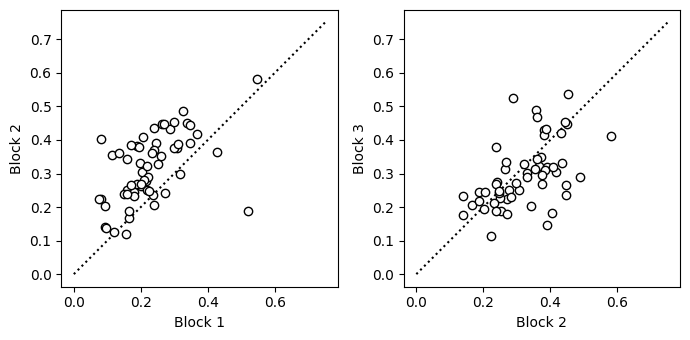

In [6]:
wt = (0.99, 0.99, 0.99)  # near-white marker fill

comparisons = [(0, 1, 1, 2), (1, 2, 2, 3)]  # (bi_x, bi_y, label_x, label_y)

fig, axs = plt.subplots(1, 2, figsize=(7, 3.5))

for ax, (bx, by, lx, ly) in zip(axs, comparisons):
    xs = bound_summary[:, bx, SNR_INDEX, 0, 0]  # mean bound, block lx
    ys = bound_summary[:, by, SNR_INDEX, 0, 0]  # mean bound, block ly

    valid = np.isfinite(xs) & np.isfinite(ys)

    # Identity line
    ax.plot([0, 0.75], [0, 0.75], 'k:')

    # One point per subject
    ax.plot(xs[valid], ys[valid], 'ko', markerfacecolor=wt)

    ax.set_xlabel(f'Block {lx}')
    ax.set_ylabel(f'Block {ly}')

    # Stats: median diff with IQR, Wilcoxon signed-rank, Spearman correlation
    diff = ys[valid] - xs[valid]
    pcts = np.percentile(diff, [25, 50, 75])
    _, p_rank = scipy.stats.wilcoxon(xs[valid], ys[valid])
    r, p_corr = scipy.stats.spearmanr(xs[valid], ys[valid])
    print(f'Block {lx} vs {ly}: median diff={pcts[1]:.2f} [{pcts[0]:.2f} {pcts[2]:.2f}], '
          f'p={p_rank:.2f}, Spearman r={r:.2f} (p={p_corr:.3f})')

    # RR correlation
    xrs = coin_summary[:, bx, SNR_INDEX][valid] / BLOCK_DEFAULTS[1]['steps_per_block']
    yrs = coin_summary[:, by, SNR_INDEX][valid] / BLOCK_DEFAULTS[1]['steps_per_block']
    rr, pr = scipy.stats.spearmanr(xrs, yrs)
    print(f'   RR: Spearman r={rr:.2f} (p={pr:.3f})')

plt.tight_layout()
plt.show()

## Within-block bound adaptation: methods

**Note on block numbering.** The top-row panels (A–C) above use `data_table_ol`, loaded
with the default `combine_snr=True`, which merges the raw 6-block OL task into 3 blocks
(raw blocks 4-6 are folded into 1-3). The tau/adaptation panels below (D–F) instead use a
separately loaded `data_table_ol_blocks = get_data_table(task_type='OL', combine_snr=False)`,
keeping the raw, unmerged 6-block numbering, so "Block 1/2/3" in the bottom row refers only
to each block's first raw exposure. This is necessary because within-block adaptation is
fit from trial 1 onward, and a combined "block" is actually two separate 40-trial exposures
concatenated — fitting a single from-trial-1 curve across that boundary would not be
meaningful.

For each subject × block, the code below computes a smoothed z-scored `abs_bound`
curve over the first 40 trials and tests whether it shows reliable time-locked
structure relative to a permutation null.  The resulting curves and τ fits are
shown as the bottom row of the formatted figure.

**Smoothed z-scored curve.** `abs_bound` is z-scored per subject × block (so the
curve reflects within-block adaptation relative to that subject's own block-average
bound), then smoothed with a ±3-trial sliding window.  We also compute 1000
permutations of each subject's own trial order within the block — preserving that
subject's noise level but destroying any time structure — giving a null distribution
specific to each subject.  The max-stat (Tmax, 95th percentile over all 40 trials)
of the group-mean null curves provides a multiple-comparison-corrected threshold.

**τ-fit eligibility.** Block 1 is gated by a within-block permutation test
(no preceding block).  Blocks 2 and 3 are gated by a per-subject Mann-Whitney U
test on steady-state |bound| between block[i−1] and block[i] — a subject can shift
reliably between blocks without that shift resolving as a clean within-block
exponential settle, so these criteria are kept separate.  Fits that hit the `tau_max`
boundary are excluded from the τ summary (shown as open triangles in the figure)
since they represent a lower bound, not a measurement.

In [7]:
from pigeon.adaptation import (
    compute_per_subject_curves_with_nulls,
    per_subject_significance,
    group_null_band,
    between_block_significance,
    fit_exp_tau,
)

SUPP_MAX_TRIAL = 40
SUPP_BLOCKS    = [1, 2, 3]
SUPP_HALF_WIN  = 3
SUPP_MIN_WIN   = 3
N_PERM         = 1000
PERM_SEED      = 123
SIG_ALPHA      = 0.05
BETWEEN_MIN_TRIALS = 5  # min good trials per block required to run the between-block test

In [8]:
# Load OL data retaining all 6 raw blocks (combine_snr=False) for per-block analysis
data_table_ol_blocks = get_data_table(task_type='OL', combine_snr=False)

supp_trial_nums, supp_real, supp_perm, supp_subjects = compute_per_subject_curves_with_nulls(
    data_table_ol_blocks, SUPP_MAX_TRIAL, SUPP_BLOCKS,
    half_win=SUPP_HALF_WIN, min_win=SUPP_MIN_WIN, n_perm=N_PERM, seed=PERM_SEED)

# Group mean ± SEM for ribbon plots (all subjects, for display)
_n_valid       = np.sum(np.isfinite(supp_real), axis=0)
supp_mean      = np.nanmean(supp_real, axis=0)
supp_sem       = np.nanstd(supp_real, axis=0) / np.sqrt(np.maximum(_n_valid, 1))
supp_sem[_n_valid < 2] = np.nan

# Permutation-based group null band (max-stat corrected across the 40 trials) -- this
# and the within-block significance test below still describe the *within-block* curve
# shown in the top row, independent of which criterion gates the tau fits below.
supp_null_thresh = group_null_band(supp_perm, alpha=SIG_ALPHA)
supp_pvals, supp_sig = per_subject_significance(supp_real, supp_perm, alpha=SIG_ALPHA)

# Between-block significance: for blocks 2 and 3, does this subject's steady-state
# |bound| reliably differ from the immediately preceding block? (block 1 has no
# preceding block, so this is undefined there -- column 0 is all False/NaN.)
supp_between_pvals, supp_sig_between = between_block_significance(
    data_table_ol_blocks, SUPP_BLOCKS, alpha=SIG_ALPHA, min_trials=BETWEEN_MIN_TRIALS)

# Tau-fit eligibility: block 1 uses the within-block adaptation test (no alternative
# exists); blocks 2 and 3 use the between-block change test instead.
supp_sig_tau = supp_sig.copy()
supp_sig_tau[:, 1:] = supp_sig_between[:, 1:]

# Per-subject exponential fits -- only for subjects classified as eligible above.
# `censored` flags fits that hit tau_max: a real (eligible) deviation that isn't well
# described by a fast exponential settle within the 40-trial window (e.g. slow drift) --
# these are excluded from the tau summary/plot rather than silently padding it at the cap.
supp_taus     = np.full((len(supp_subjects), len(SUPP_BLOCKS)), np.nan)
supp_censored = np.zeros((len(supp_subjects), len(SUPP_BLOCKS)), dtype=bool)
for bi in range(len(SUPP_BLOCKS)):
    for si in range(len(supp_subjects)):
        if supp_sig_tau[si, bi]:
            tau, censored = fit_exp_tau(supp_trial_nums, supp_real[si, :, bi], tau_max=SUPP_MAX_TRIAL)
            supp_taus[si, bi]     = tau
            supp_censored[si, bi] = censored

print('Per-block adaptation summary:')
for bi, block in enumerate(SUPP_BLOCKS):
    n_total   = np.sum(np.any(np.isfinite(supp_real[:, :, bi]), axis=1))
    n_within  = np.sum(supp_sig[:, bi])
    mean_curve = supp_mean[:, bi]
    max_abs   = np.nanmax(np.abs(mean_curve))
    exceeds   = max_abs > supp_null_thresh[bi]
    print(f'  Block {block}: {n_within}/{n_total} subjects show within-block adaptation '
          f'({100 * n_within / max(n_total, 1):.0f}%)')
    print(f'    group mean curve: max|curve|={max_abs:.3f} vs. null threshold '
          f'±{supp_null_thresh[bi]:.3f} -> {"exceeds null" if exceeds else "within null"}')

    if bi == 0:
        n_qual, crit_label = n_within, 'within-block adaptation (no preceding block)'
    else:
        n_qual = np.sum(supp_sig_between[:, bi])
        crit_label = f'significant change vs. block {SUPP_BLOCKS[bi - 1]} (Mann-Whitney U)'
    print(f'    tau-fit eligibility: {n_qual}/{n_total} subjects qualify ({crit_label})')

    is_censored = supp_censored[:, bi]
    vt = supp_taus[:, bi][np.isfinite(supp_taus[:, bi]) & ~is_censored]
    n_cens = np.sum(is_censored)
    if len(vt):
        q25, med, q75 = np.percentile(vt, [25, 50, 75])
        print(f'    τ (eligible, non-censored): median={med:.1f}  '
              f'IQR=[{q25:.1f}, {q75:.1f}]  n={len(vt)}  '
              f'(+{n_cens} censored at tau_max, excluded)')
    else:
        print(f'    τ: no uncensored fits ({n_cens} eligible subjects censored at tau_max)')

  1: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_14h39.24.096.csv


  2: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_15h37.48.260.csv
  3: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h34.46.761.csv
  4: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h35.25.285.csv
  5: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h36.33.669.csv


  6: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h36.41.364.csv


  7: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h36.49.086.csv
  8: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h38.01.606.csv
  9: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h38.09.635.csv


 10: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h38.21.334.csv


...

 50: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_09h38.24.956.csv
 51: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h36.07.278.csv
 52: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h37.16.053.csv


 53: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h37.20.203.csv
 54: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h37.32.380.csv
 55: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h37.37.464.csv
 56: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h38.28.207.csv
 57: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h39.12.114.csv


 58: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h40.02.817.csv


 59: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h40.07.382.csv
 60: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h41.01.524.csv


Per-block adaptation summary:
  Block 1: 8/56 subjects show within-block adaptation (14%)
    group mean curve: max|curve|=0.175 vs. null threshold ±0.197 -> within null
    tau-fit eligibility: 8/56 subjects qualify (within-block adaptation (no preceding block))
    τ (eligible, non-censored): median=6.2  IQR=[5.1, 15.6]  n=3  (+5 censored at tau_max, excluded)
  Block 2: 14/58 subjects show within-block adaptation (24%)
    group mean curve: max|curve|=0.385 vs. null threshold ±0.192 -> exceeds null
    tau-fit eligibility: 41/58 subjects qualify (significant change vs. block 1 (Mann-Whitney U))
    τ (eligible, non-censored): median=8.0  IQR=[4.0, 15.1]  n=26  (+14 censored at tau_max, excluded)
  Block 3: 6/57 subjects show within-block adaptation (11%)
    group mean curve: max|curve|=0.170 vs. null threshold ±0.187 -> within null
    tau-fit eligibility: 16/57 subjects qualify (significant change vs. block 2 (Mann-Whitney U))
    τ (eligible, non-censored): median=3.6  IQR=[3.3, 

## Formatted figure

Two-row × three-column figure saved to `Figure04.pdf`.

**Top row** (one panel per block): Scatter of mean bound (x) vs. reward rate (y) per
subject.  Light blue ribbon = 5th–95th percentile of simulated reward rate vs. bound
(100 subjects).  Two sets of dashed crosshair lines project to both axes, using the
same color convention as Figure02c (blue = ideal/simulated benchmark, black =
empirical participant data):
- **Blue** — the simulated median RR curve itself, and its peak (optimal bound).
- **Black** — median bound and median reward rate across participants.

**Bottom row** (one panel per block): Group-mean ± SEM ribbon of the smoothed
z-scored bound curve over the first 40 trials, in black (empirical data). Light
gray band = permutation null (max-stat corrected, 95%).  Lower-right inset:
box/jitter plot of τ (exponential time constant) for subjects with a successful,
non-censored fit; censored fits (τ pinned at tau_max = 40) are omitted from the
plot entirely rather than shown as a separate marker. The label above each inset
reads `n = <fit>/<total>`: the number of subjects with a plotted τ over the total
number of subjects with usable data in that block.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


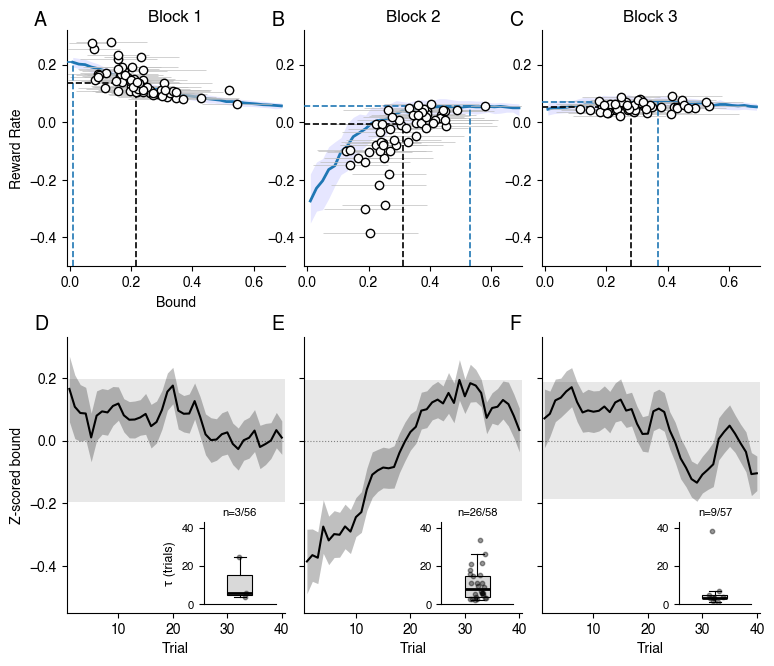

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure04.pdf

τ fits (eligible, non-censored):
  Block 1: median=6.2 [5.1, 15.6]  (n=3 good fits, 5 censored, 8 eligible)
  Block 2: median=8.0 [4.0, 15.1]  (n=26 good fits, 14 censored, 41 eligible)
  Block 3: median=3.6 [3.3, 5.0]  (n=9 good fits, 7 censored, 16 eligible)


In [9]:
import matplotlib.gridspec as gridspec

CM  = 1 / 2.54
WID = 17.6
HTS = [6.0, 7.0]
PSH = 1.8
PSW = 0.5
FS  = 12

fig_h       = sum(HTS) + PSH
panel_w     = (WID - 2 * PSW) / 3
hspace_frac = PSH / np.mean(HTS)
wspace_frac = PSW / panel_w

fig_comb = plt.figure(figsize=(WID * CM, fig_h * CM))
gs_comb  = gridspec.GridSpec(2, 3, figure=fig_comb,
                              height_ratios=HTS,
                              hspace=hspace_frac, wspace=wspace_frac,
                              left=0, right=1, bottom=0, top=1)
axs_top = [fig_comb.add_subplot(gs_comb[0, c]) for c in range(3)]
axs_bot = [fig_comb.add_subplot(gs_comb[1, c]) for c in range(3)]

plt.rcParams.update({'font.size': FS, 'axes.labelsize': FS, 'axes.titlesize': FS, **FONT_RC})

gr_c = (0.75, 0.75, 0.75)
wt_c = (0.99, 0.99, 0.99)
rp_c = (0.9,  0.9,  1.0)

# Color convention (consistent with Figure02c): blue = ideal/simulated benchmark,
# black = empirical participant data.
OPT_COLOR  = 'tab:blue'   # simulated RR curve and the peak of that curve
DATA_COLOR = 'k'          # median of the empirical data

# ── Pre-compute simulation ribbons for all blocks (single RNG pass) ───────────
# Done up-front so we can determine axis limits before drawing anything.
rng_comb = np.random.default_rng(0)
sbd_all = []
for bi, block in enumerate(BLOCKS):
    sbd = np.full((len(SIM_BOUNDS), 3), np.nan)
    for ss, bnd in enumerate(SIM_BOUNDS):
        sim_table = get_simulated_data_table(
            specs={'num_subjects': NUM_SIM_SUBJ, 'blocks': block},
            generative_mean=GENERATIVE_MEAN,
            bound_mean=bnd,
            rng=rng_comb,
        )
        sim_coins = sim_table.groupby('subject_index')['coin_count'].last().to_numpy()
        sbd[ss] = np.percentile(sim_coins, [5, 50, 95]) / BLOCK_DEFAULTS[1]['steps_per_block']
    sbd_all.append(sbd)

# Axis limits that keep every optimal-RR crosshair in frame
all_opt_idx = [int(np.nanargmax(sbd[:, 1])) for sbd in sbd_all]
all_opt_x   = [float(SIM_BOUNDS[i]) for i in all_opt_idx]
all_opt_y   = [float(sbd_all[bi][all_opt_idx[bi], 1]) for bi in range(3)]
x_left      = min(0.0, min(all_opt_x) - 0.02)   # extend left if any optimal is at/near x=0
y_top       = max(max(all_opt_y) * 1.08, 0.32)
TOP_XLIM    = (x_left, 0.7)
TOP_YLIM    = (-0.5, y_top)

# ── Top row: RR vs. bound ─────────────────────────────────────────────────────
# Ideal RR curve is blue, matching the "ideal observer" curve in Figure02c; its
# dashed crosshair (optimal bound) is the same blue. The empirical data —
# participant scatter and its dashed median crosshair — are black.
for bi, block in enumerate(BLOCKS):
    ax  = axs_top[bi]
    sbd = sbd_all[bi]

    ax.fill_between(SIM_BOUNDS, sbd[:, 0], sbd[:, 2], color=rp_c, linewidth=0)
    ax.plot(SIM_BOUNDS, sbd[:, 1], '-', color=OPT_COLOR, linewidth=2)

    # Blue dashed crosshairs for the optimal bound: project to both axes
    best_x = all_opt_x[bi]
    best_y = all_opt_y[bi]
    ax.plot([best_x, best_x], [TOP_YLIM[0], best_y], '--', color=OPT_COLOR, lw=1.2, zorder=3)
    ax.plot([TOP_XLIM[0], best_x], [best_y, best_y], '--', color=OPT_COLOR, lw=1.2, zorder=3)

    # Data scatter: one point per subject, horizontal error bars = ±1 SD bound
    mean_b   = bound_summary[:, bi, SNR_INDEX, 0, 0]
    std_b    = bound_summary[:, bi, SNR_INDEX, 0, 1]
    rr       = coin_summary[:, bi, SNR_INDEX] / BLOCK_DEFAULTS[1]['steps_per_block']
    valid_bi = np.isfinite(mean_b) & np.isfinite(rr)

    ax.errorbar(mean_b[valid_bi], rr[valid_bi],
                xerr=std_b[valid_bi], fmt='none',
                ecolor=gr_c, elinewidth=0.5, capsize=0)
    ax.plot(mean_b[valid_bi], rr[valid_bi], 'ko', markerfacecolor=wt_c, zorder=4)

    # Black dashed crosshairs for the participant median
    med_x = float(np.nanmedian(mean_b[valid_bi]))
    med_y = float(np.nanmedian(rr[valid_bi]))
    ax.plot([med_x, med_x], [TOP_YLIM[0], med_y], '--', color=DATA_COLOR, lw=1.2, zorder=3)
    ax.plot([TOP_XLIM[0], med_x], [med_y, med_y], '--', color=DATA_COLOR, lw=1.2, zorder=3)

    ax.set_xlim(*TOP_XLIM)
    ax.set_ylim(*TOP_YLIM)
    if x_left < 0:
        ax.set_xticks([0, 0.2, 0.4, 0.6])   # hide the negative-margin tick
    ax.set_title(f'Block {block}')
    if bi == 0:
        ax.set_xlabel('Bound')
        ax.set_ylabel('Reward Rate')
    for sp in ['top', 'right']:
        ax.spines[sp].set_visible(False)

# ── Bottom row: within-block learning curves with τ insets ───────────────────
# Curve + ribbon are black (empirical data), consistent with the top row's
# black data crosshairs. The permutation null band is a light gray, chosen to
# stay visually distinct from the black curve/ribbon (which render as a
# mid-gray at alpha=0.25) rather than blending into it.
_NULL_COLOR  = (0.85, 0.85, 0.85)
_CURVE_COLOR = 'k'

_top_lo  = min(np.nanmin(supp_mean - supp_sem), -np.max(supp_null_thresh))
_top_hi  = max(np.nanmax(supp_mean + supp_sem),  np.max(supp_null_thresh))
_top_pad = 0.08 * (_top_hi - _top_lo)
_CURVE_YLIM = (_top_lo - _top_pad, _top_hi + _top_pad)

_rng_jit = np.random.default_rng(42)

for bi, block in enumerate(SUPP_BLOCKS):
    ax = axs_bot[bi]
    mn  = supp_mean[:, bi]
    sem = supp_sem[:, bi]
    ok  = np.isfinite(mn) & np.isfinite(sem)
    thr = supp_null_thresh[bi]

    ax.axhline(0, color='k', linestyle=':', linewidth=0.8, zorder=0)
    ax.axhspan(-thr, thr, color=_NULL_COLOR, alpha=0.6, linewidth=0, zorder=0)
    ax.fill_between(supp_trial_nums[ok], mn[ok] - sem[ok], mn[ok] + sem[ok],
                    alpha=0.25, color=_CURVE_COLOR, linewidth=0)
    ax.plot(supp_trial_nums[ok], mn[ok], '-', color=_CURVE_COLOR, linewidth=1.5)

    ax.set_xlim(0.5, SUPP_MAX_TRIAL + 0.5)
    ax.set_ylim(*_CURVE_YLIM)
    if bi == 0:
        ax.set_ylabel('Z-scored bound')
    else:
        ax.tick_params(axis='y', labelleft=False)
    ax.set_xlabel('Trial')
    for sp in ['top', 'right']:
        ax.spines[sp].set_visible(False)

    # ── τ inset (lower-right corner of the learning-curve panel) ──────────────
    ax_ins = ax.inset_axes([0.63, 0.03, 0.33, 0.30])

    is_cens = supp_censored[:, bi]
    vt      = supp_taus[:, bi][np.isfinite(supp_taus[:, bi]) & ~is_cens]
    n_total = int(np.sum(np.any(np.isfinite(supp_real[:, :, bi]), axis=1)))

    if len(vt):
        ax_ins.boxplot(vt, positions=[1], widths=0.35,
                       patch_artist=True,
                       medianprops=dict(color='k', linewidth=2),
                       boxprops=dict(facecolor=(0.85, 0.85, 0.85), linewidth=0.8),
                       whiskerprops=dict(linewidth=0.8),
                       capprops=dict(linewidth=0.8),
                       flierprops=dict(marker='none'))
        jit = _rng_jit.uniform(-0.12, 0.12, len(vt))
        ax_ins.scatter(np.ones(len(vt)) + jit, vt, s=10, color='k', alpha=0.4, zorder=4)
    else:
        ax_ins.text(1, SUPP_MAX_TRIAL / 2, 'no fits', ha='center', va='center',
                    fontsize=FS - 4)

    # n label above the inset: fit subjects (successful, non-censored) over the
    # total number of subjects with usable data in this block.
    ax_ins.text(0.5, 1.05, f'n={len(vt)}/{n_total}', transform=ax_ins.transAxes,
                ha='center', va='bottom', fontsize=FS - 4)

    ax_ins.set_xlim(0.5, 1.5)
    ax_ins.set_ylim(0, SUPP_MAX_TRIAL * 1.08)
    ax_ins.set_xticks([])
    if bi == 0:
        ax_ins.set_ylabel('τ (trials)', fontsize=FS - 3)
    ax_ins.tick_params(labelsize=FS - 4)
    for sp in ['top', 'right']:
        ax_ins.spines[sp].set_visible(False)

for bi in range(3):
    add_panel_label(axs_top[bi], chr(65 + bi))
    add_panel_label(axs_bot[bi], chr(68 + bi))

out_comb = FIGURES_DIR / 'Figure04.pdf'
fig_comb.savefig(out_comb, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out_comb}')

# ── τ summary for manuscript reporting ───────────────────────────────────────
print('\nτ fits (eligible, non-censored):')
for bi, block in enumerate(SUPP_BLOCKS):
    is_cens = supp_censored[:, bi]
    vt      = supp_taus[:, bi][np.isfinite(supp_taus[:, bi]) & ~is_cens]
    n_cens  = int(np.sum(is_cens))
    n_qual  = (int(np.sum(supp_sig[:, bi])) if bi == 0
               else int(np.sum(supp_sig_between[:, bi])))
    if len(vt) >= 3:
        q25, med, q75 = np.percentile(vt, [25, 50, 75])
        print(f'  Block {block}: median={med:.1f} [{q25:.1f}, {q75:.1f}]  '
              f'(n={len(vt)} good fits, {n_cens} censored, {n_qual} eligible)')
    else:
        print(f'  Block {block}: insufficient fits  '
              f'(n={len(vt)} good, {n_cens} censored, {n_qual} eligible)')